# Tugas Lab 1: Eksperimen Metrik Jarak, Ukuran Data & Dimensi pada ANN

Lakukan percobaan pada metric distance yang berbeda, 1000 vs 1.000.000 data, 2D vs 5D data, untuk algoritma:
1. ANNOY
2. FAISS
3. HNSW

Catat performansinya dalam bentuk tabel perbandingan Build Time dan Query Time.

# Import Library

In [1]:
import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt
from annoy import AnnoyIndex
import faiss
import hnswlib

# Desain Fungsi Pengujian Benchmark Multi-Metrik & Skala

In [2]:
def benchmark_ann(n_data, dim, metric='euclidean', k=10):
    np.random.seed(42)
    X = np.random.random((n_data, dim)).astype(np.float32)
    q = np.random.random((1, dim)).astype(np.float32)

    # Normalisasi vektor jika menggunakan Cosine/Inner Product
    if metric == 'cosine':
        X_norm = X / np.linalg.norm(X, axis=1, keepdims=True)
        q_norm = q / np.linalg.norm(q, axis=1, keepdims=True)
    else:
        X_norm = X
        q_norm = q

    # 1. ANNOY
    ann_metric = 'euclidean' if metric == 'euclidean' else 'angular'
    ann = AnnoyIndex(dim, ann_metric)
    t0 = time.time()
    for i in range(n_data):
        ann.add_item(i, X[i])
    ann.build(10)
    ann_build_time = time.time() - t0

    t0 = time.time()
    _ = ann.get_nns_by_vector(q[0], k)
    ann_query_time = (time.time() - t0) * 1000  # dalam ms

    # 2. FAISS
    t0 = time.time()
    if metric == 'euclidean':
        f_idx = faiss.IndexFlatL2(dim)
    else:
        f_idx = faiss.IndexFlatIP(dim)
    f_idx.add(X_norm)
    faiss_build_time = time.time() - t0

    t0 = time.time()
    _, _ = f_idx.search(q_norm, k)
    faiss_query_time = (time.time() - t0) * 1000  # dalam ms

    # 3. HNSW
    h_space = 'l2' if metric == 'euclidean' else 'cosine'
    h_idx = hnswlib.Index(space=h_space, dim=dim)
    t0 = time.time()
    h_idx.init_index(max_elements=n_data, ef_construction=100, M=16)
    h_idx.add_items(X)
    hnsw_build_time = time.time() - t0

    h_idx.set_ef(50)
    t0 = time.time()
    _, _ = h_idx.knn_query(q, k=k)
    hnsw_query_time = (time.time() - t0) * 1000  # dalam ms

    return {
        'ANNOY_build_s': ann_build_time,
        'ANNOY_query_ms': ann_query_time,
        'FAISS_build_s': faiss_build_time,
        'FAISS_query_ms': faiss_query_time,
        'HNSW_build_s': hnsw_build_time,
        'HNSW_query_ms': hnsw_query_time
    }

# Menjalankan Eksperimen pada 4 Konfigurasi

In [3]:
configs = [
    {"label": "1000/2D (Euclidean)", "n": 1000, "dim": 2, "metric": "euclidean"},
    {"label": "1000/2D (Cosine)", "n": 1000, "dim": 2, "metric": "cosine"},
    {"label": "1000000/5D (Euclidean)", "n": 1_000_000, "dim": 5, "metric": "euclidean"},
    {"label": "1000000/5D (Cosine)", "n": 1_000_000, "dim": 5, "metric": "cosine"}
]

records = []
for cfg in configs:
    print(f"Sedang menguji: {cfg['label']}...")
    res = benchmark_ann(cfg['n'], cfg['dim'], cfg['metric'])
    records.append({
        "Jumlah Data / Dimensi": cfg["label"],
        "ANNOY (Build / Query)": f"{res['ANNOY_build_s']:.4f}s / {res['ANNOY_query_ms']:.3f}ms",
        "FAISS (Build / Query)": f"{res['FAISS_build_s']:.4f}s / {res['FAISS_query_ms']:.3f}ms",
        "HNSW (Build / Query)": f"{res['HNSW_build_s']:.4f}s / {res['HNSW_query_ms']:.3f}ms",
        "Annoy_Build_s": res['ANNOY_build_s'],
        "Faiss_Build_s": res['FAISS_build_s'],
        "HNSW_Build_s": res['HNSW_build_s'],
        "Annoy_Query_ms": res['ANNOY_query_ms'],
        "Faiss_Query_ms": res['FAISS_query_ms'],
        "HNSW_Query_ms": res['HNSW_query_ms']
    })

df_results = pd.DataFrame(records)
print("Eksperimen Selesai!")

Sedang menguji: 1000/2D (Euclidean)...
Sedang menguji: 1000/2D (Cosine)...
Sedang menguji: 1000000/5D (Euclidean)...


Sedang menguji: 1000000/5D (Cosine)...


Eksperimen Selesai!


# Tabel Hasil Performansi

In [4]:
# Menampilkan tabel performansi ringkas
df_display = df_results[["Jumlah Data / Dimensi", "ANNOY (Build / Query)", "FAISS (Build / Query)", "HNSW (Build / Query)"]]
display(df_display)

,Jumlah Data / Dimensi,ANNOY (Build / Query),FAISS (Build / Query),HNSW (Build / Query)
0,1000/2D (Euclidean),0.0062s / 0.062ms,0.0001s / 0.054ms,0.0058s / 0.049ms
1,1000/2D (Cosine),0.0067s / 0.035ms,0.0001s / 0.033ms,0.0051s / 0.037ms
2,1000000/5D (Euclidean),3.9530s / 0.090ms,0.0054s / 4.057ms,9.2421s / 0.122ms
3,1000000/5D (Cosine),4.6233s / 0.164ms,0.0055s / 1.042ms,8.3692s / 0.081ms


# Visualisasi Komparasi Performansi

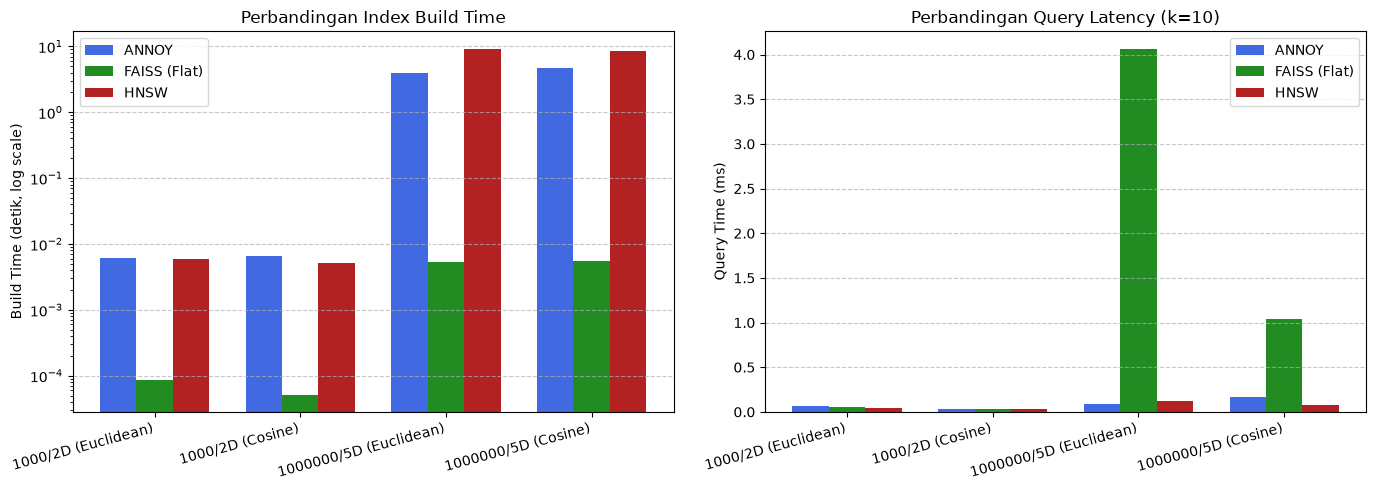

In [5]:
# Visualisasi Perbandingan Build Time & Query Time
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
labels = df_results["Jumlah Data / Dimensi"]
x = np.arange(len(labels))
width = 0.25

# 1. Build Time (Detik, Skala Logaritmik)
axes[0].bar(x - width, df_results["Annoy_Build_s"], width, label='ANNOY', color='royalblue')
axes[0].bar(x, df_results["Faiss_Build_s"], width, label='FAISS (Flat)', color='forestgreen')
axes[0].bar(x + width, df_results["HNSW_Build_s"], width, label='HNSW', color='firebrick')
axes[0].set_ylabel('Build Time (detik, log scale)')
axes[0].set_yscale('log')
axes[0].set_title('Perbandingan Index Build Time')
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels, rotation=15, ha='right')
axes[0].legend()
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# 2. Query Time (Milidetik)
axes[1].bar(x - width, df_results["Annoy_Query_ms"], width, label='ANNOY', color='royalblue')
axes[1].bar(x, df_results["Faiss_Query_ms"], width, label='FAISS (Flat)', color='forestgreen')
axes[1].bar(x + width, df_results["HNSW_Query_ms"], width, label='HNSW', color='firebrick')
axes[1].set_ylabel('Query Time (ms)')
axes[1].set_title('Perbandingan Query Latency (k=10)')
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels, rotation=15, ha='right')
axes[1].legend()
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()